> STATUS: ATUAL — execução final COM, BEST época 3.
> Revisão editorial em 30/10/2026: somente apresentação de resultados existentes; este notebook não foi reexecutado nesta revisão.
> Consulte o [guia oficial](../../../GUIA_NOTEBOOKS_RESULTADOS.md). Os notebooks 03/04 contêm chamadas de inferência; seus outputs estão preservados e não devem ser reexecutados nesta etapa editorial.


In [1]:
# [celula injetada pelo executor] redireciona config para a politica shared-extrasystoles-bbb-v1
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
config.CLASSIFICATION_POLICY = "shared-extrasystoles-bbb-v1"
config.MITBIH_PROCESSED_FILE = config.PROCESSED_DIR / "mitbih_shared-extrasystoles-bbb-v1.npz"
config.LUDB_PROCESSED_FILE = config.PROCESSED_DIR / "ludb_shared-extrasystoles-bbb-v1.npz"


# 04 — Teste no LUDB com o modelo treinado

Demonstra o uso do modelo **já treinado**: carrega o checkpoint, congela os
pesos e mede o desempenho no LUDB — base independente, que nunca participou de
nenhuma decisão de treino.

É o equivalente em notebook de:

```bash
python src/test_ludb.py
```

Os artefatos desta execução já estão presentes no pacote. Não é necessário executar o pipeline para consultar estes outputs; veja o guia oficial.

## 1. Carregando o modelo compartilhado

`model_gradcam.load_checkpoint` reconstrói a arquitetura a partir dos
hiperparâmetros gravados no próprio arquivo — quem receber apenas o `.pt`
consegue rodar o modelo sem conhecer o código de treino.

In [2]:

import matplotlib.pyplot as plt
import json
import numpy as np

import sys
from pathlib import Path

# O codigo do projeto vive em src/ (nao ha pacote instalavel).
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
import classification
import beat_io
import test_ludb as metrics

import model_gradcam as mg

CKPT = config.MODELS_DIR / "cnn1d_mitbih_shared-extrasystoles-bbb-v1" / mg.CHECKPOINT_NAME

modelo, ckpt = mg.load_checkpoint(CKPT, expected_policy=config.CLASSIFICATION_POLICY)
info = ckpt["info"]
limiar = float(ckpt["threshold"])  # fixo; não é reajustado aqui

print(f"treinado em : {info['dataset_treino']}")
print(f"split       : {info['train_config']['split_scheme']}")
print(f"parâmetros  : {info['n_parametros']}")
print(f"limiar      : {limiar:.4f} (fixo em todo o projeto — treino, validação e teste)")
print(f"modo eval   : {not modelo.training}")

m_val = info["metrics"]["validacao"]
print(
    f"\nreferência no MIT-BIH (validação): acurácia {m_val['acuracia']:.4f} | "
    f"sens {m_val['sensibilidade']:.4f} | esp {m_val['especificidade']:.4f}"
)

treinado em : mit-bih-arrhythmia
split       : StratifiedGroupKFold(n_splits=5) fold 0
parâmetros  : 121633
limiar      : 0.5000 (fixo em todo o projeto — treino, validação e teste)
modo eval   : True

referência no MIT-BIH (validação): acurácia 0.8995 | sens 0.7770 | esp 0.9991


## 2. Inferência no LUDB

In [3]:
ludb = beat_io.load_beat_dataset(config.LUDB_PROCESSED_FILE)
X = ludb["series"]
y = ludb["labels"].astype(int)
ritmos = ludb["simbolos"]
pacientes = ludb["pacientes"]

scores = mg.predict_scores(modelo, X)
m_ludb = metrics.binary_metrics(y, scores, limiar)
y_pred = (scores >= limiar).astype(int)

print(metrics.formata_metricas("LUDB (cross-dataset)", m_ludb))
print()
print(metrics.formata_metricas("LUDB @ 0.50", metrics.binary_metrics(y, scores, 0.5)))

[LUDB (cross-dataset)] n=390  limiar=0.50
  acuracia            : 0.3923
  acuracia balanceada : 0.5755
  sensibilidade (rec) : 0.1696
  especificidade      : 0.9813
  precisao            : 0.9600
  f1                  : 0.2883
  auc-roc             : 0.7143
  confusao            : tp=48 fn=235 tn=105 fp=2

[LUDB @ 0.50] n=390  limiar=0.50
  acuracia            : 0.3923
  acuracia balanceada : 0.5755
  sensibilidade (rec) : 0.1696
  especificidade      : 0.9813
  precisao            : 0.9600
  f1                  : 0.2883
  auc-roc             : 0.7143
  confusao            : tp=48 fn=235 tn=105 fp=2


## 3. Onde o modelo acerta e onde não acerta

A quebra por ritmo é uma análise de possível confusão. `Rhythms` é preservado
como metadado e não determina o label das políticas compartilhadas.


[LUDB por ritmo] desempenho por grupo
  grupo                             n  classe   acerto   score
  sinus rhythm                    255   mista   0.4549  0.1185
  atrial fibrillation              58       1   0.3793  0.3860
  sinus arrhythmia                 31   mista   0.2258  0.0460
  sinus tachycardia                24       1   0.0000  0.0054
  irregular sinus rhythm           13       1   0.2308  0.2382
  sinus bradycardia                 9       1   0.5556  0.5425


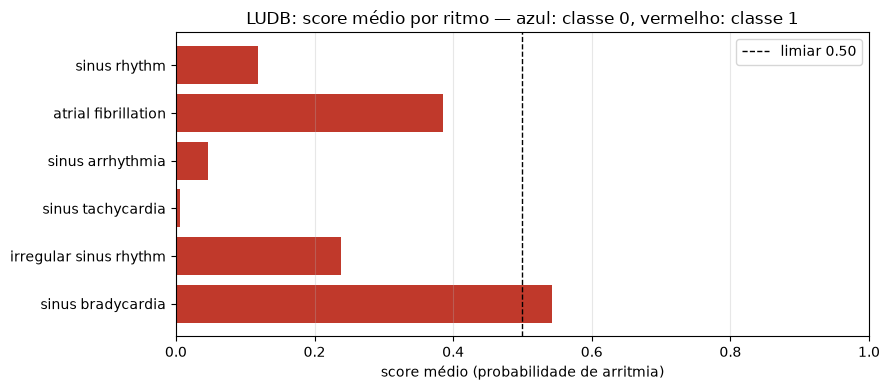

In [4]:
por_ritmo = metrics.por_grupo(y, scores, ritmos, threshold=limiar)
print(metrics.formata_por_grupo("LUDB por ritmo", por_ritmo))

fig, eixo = plt.subplots(figsize=(9, 4))
nomes = [linha["grupo"] for linha in por_ritmo]
medias = [linha["score_medio"] for linha in por_ritmo]
cores = ["#2980b9" if linha["classe_verdadeira"] == 0 else "#c0392b" for linha in por_ritmo]
eixo.barh(nomes[::-1], medias[::-1], color=cores[::-1])
eixo.axvline(limiar, color="k", ls="--", lw=1, label=f"limiar {limiar:.2f}")
eixo.set_xlabel("score médio (probabilidade de arritmia)")
eixo.set_xlim(0, 1)
eixo.legend()
eixo.set_title("LUDB: score médio por ritmo — azul: classe 0, vermelho: classe 1")
eixo.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

## 4. Distribuição dos scores

Comparando com o histograma da validação (notebook 03), aqui as duas
classes se sobrepõem — parte disso é diferença de população e equipamento,
parte é diferença de **granularidade**: o MIT-BIH rotula o batimento, enquanto
o LUDB fornece condições do registro propagadas aos beats aceitos.

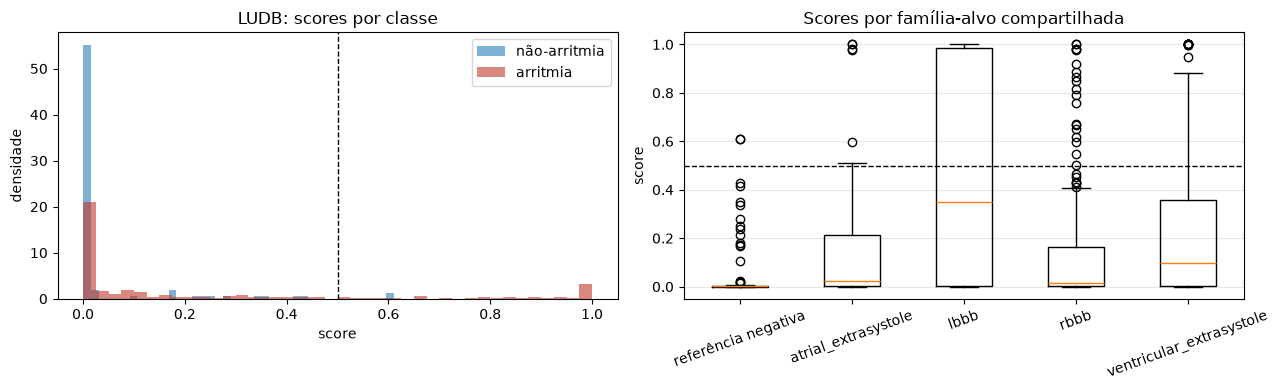

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

for classe, cor, rotulo in [(0, "#2980b9", "não-arritmia"), (1, "#c0392b", "arritmia")]:
    eixos[0].hist(scores[y == classe], bins=40, alpha=0.6, color=cor, label=rotulo, density=True)
eixos[0].axvline(limiar, color="k", ls="--", lw=1)
eixos[0].set_xlabel("score")
eixos[0].set_ylabel("densidade")
eixos[0].legend()
eixos[0].set_title("LUDB: scores por classe")

familias = [json.loads(str(value)) for value in ludb["target_families"]]
grupos_scores = {"referência negativa": scores[y == 0]}
for familia in sorted({f for fs in familias for f in fs}):
    mask = np.array([familia in fs for fs in familias])
    grupos_scores[familia] = scores[mask]
eixos[1].boxplot(list(grupos_scores.values()))
eixos[1].set_xticks(range(1, len(grupos_scores) + 1), list(grupos_scores), rotation=20)
eixos[1].axhline(limiar, color="k", ls="--", lw=1)
eixos[1].set_ylabel("score")
eixos[1].set_title("Scores por família-alvo compartilhada")
eixos[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
plt.show()

## 5. Batimentos individuais com as regiões clínicas

O LUDB traz as delimitações de P, QRS e T anotadas por especialistas — o
*ground truth* espacial da Etapa 4. Abaixo, um exemplo de cada quadrante da
matriz de confusão com as três estruturas sombreadas. É exatamente sobre este
gráfico que o mapa do Grad-CAM será sobreposto.

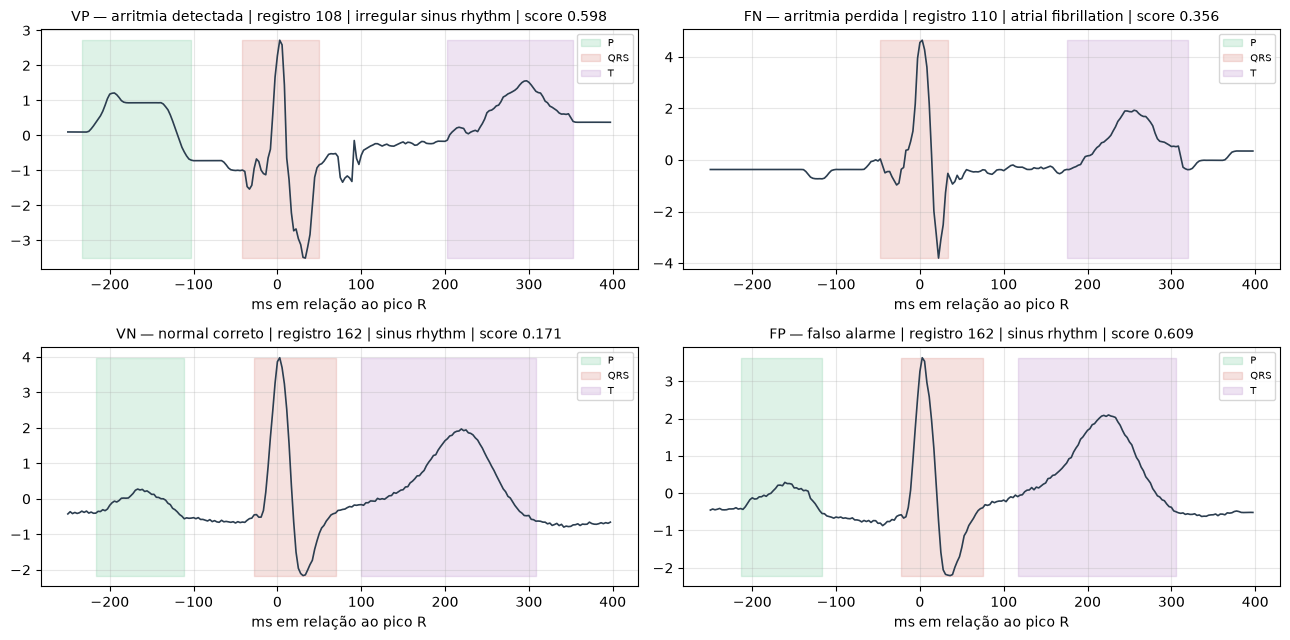

In [6]:
mascaras = {
    "P": ludb["mascara_p"],
    "QRS": ludb["mascara_qrs"],
    "T": ludb["mascara_t"],
}
cores_onda = {"P": "#27ae60", "QRS": "#c0392b", "T": "#8e44ad"}
tempo = (np.arange(X.shape[1]) - config.WINDOW_LEFT) / config.TARGET_FS * 1000

quadrantes = {
    "VP — arritmia detectada": (y == 1) & (y_pred == 1),
    "FN — arritmia perdida": (y == 1) & (y_pred == 0),
    "VN — normal correto": (y == 0) & (y_pred == 0),
    "FP — falso alarme": (y == 0) & (y_pred == 1),
}

rng = np.random.default_rng(config.RANDOM_SEED)
fig, eixos = plt.subplots(2, 2, figsize=(13, 6.5))
for eixo, (titulo, mascara) in zip(eixos.ravel(), quadrantes.items()):
    candidatos = np.flatnonzero(mascara)
    if candidatos.size == 0:
        eixo.set_axis_off()
        continue
    i = int(rng.choice(candidatos))
    eixo.plot(tempo, X[i], color="#2c3e50", lw=1.2)
    for onda, mat in mascaras.items():
        eixo.fill_between(
            tempo, X[i].min(), X[i].max(), where=mat[i].astype(bool),
            alpha=0.15, color=cores_onda[onda], label=onda,
        )
    eixo.set_title(
        f"{titulo} | registro {pacientes[i]} | {ritmos[i]} | score {scores[i]:.3f}",
        fontsize=10,
    )
    eixo.set_xlabel("ms em relação ao pico R")
    eixo.legend(fontsize=7, loc="upper right")
    eixo.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6. O piso da métrica de fidelidade

A fração da janela coberta pela máscara clínica é a **pontuação esperada ao
acaso**: qualquer mapa de calor aleatório atinge esse valor. É contra ele — e
não contra zero — que o resultado do Grad-CAM deve ser comparado na Etapa 4.

In [7]:
cobertura = ludb["mascara_clinica"].mean()
print(f"cobertura média da máscara clínica (P + QRS + T): {cobertura:.4f}")
for onda, mat in mascaras.items():
    print(f"  {onda:<3}: {mat.mean():.4f}")

sem_p = ~ludb["tem_onda_p"].astype(bool)
print(
    f"\nbatimentos sem onda P delimitada: {int(sem_p.sum())} "
    f"({sem_p.mean():.1%}) — fibrilação e flutter atrial, onde a ausência da "
    f"onda P é a própria definição eletrofisiológica"
)

cobertura média da máscara clínica (P + QRS + T): 0.5764
  P  : 0.1417
  QRS: 0.1526
  T  : 0.2821

batimentos sem onda P delimitada: 58 (14.9%) — fibrilação e flutter atrial, onde a ausência da onda P é a própria definição eletrofisiológica


## 7. Próximo passo (Etapa 4)

`src/test_ludb.py` grava as predições batimento a batimento em
`teste_ludb/ludb_predictions.npz`. Cruzando esse arquivo com as máscaras
clínicas do LUDB e com os mapas do Grad-CAM 1D — extraídos de
`modelo.last_conv`, a última camada convolucional — chega-se à métrica
quantitativa de fidelidade que é o objeto do artigo.

Vale notar que a fidelidade pode e deve ser medida **também nos batimentos que
o modelo erra**: um falso negativo cujo Grad-CAM aponta corretamente o QRS e a
onda T indica erro de decisão, não de foco. É a distinção que a inspeção
puramente visual não consegue sustentar.